<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/superposition_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A model with only 2 hidden dimensions can store 5 features

In this experiment, the model has n independent features, each of which is either absent (0) or present with some strength in [0, 1). **Sparsity** S is the probability that a feature is absent in a given example.
**When S is high**, features rarely co-occur, so a model can afford to store several of them in the same few dimensions and accept occasional interference. Today’s question is whether a model with only 2 hidden dimensions can store 5 features, and how the answer depends on S.

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

n_features, n_hidden = 5, 2

def generate_batch(batch_size, n_features, sparcity):
    x = torch.rand(batch_size, n_features)
    active = torch.rand(batch_size, n_features) > sparcity
    return x * active

batch = generate_batch(10, n_features, 0.9)
print(batch.shape)
print("empirical sparsity : " , (batch==0).float().mean().item())
print("average active features :" , (batch >0).float().mean().item())

torch.Size([10, 5])
empirical sparsity :  0.8799999952316284
average active features : 0.11999999731779099


The model is deliberately tiny. It squeezes the 5 features through a 2-dimensional bottleneck and then tries to rebuild them:

h = W x (compress: 5 → 2) and x̂ = ReLU(Wᵀ h + b) (reconstruct: 2 → 5)

The same matrix W is used in both directions (tied weights), so there is nothing to hide in: each column of W is the 2D direction the model assigns to one feature. E.g. Think of five arrows in a plane. If the model could only use dimensions as one-feature-per-axis, it could store just 2 features. If it packs the five arrows at different angles, it can represent all 5, but the arrows overlap, so reading one feature picks up a little of its neighbors. That overlap is interference, and the ReLU is what lets the model clip some of it away.

In [2]:
import torch
import torch.nn as nn

class toy_model(nn.Module):
    def __init__(self, n_features, n_hidden):
        super().__init__()
        self.W = nn.Parameter(torch.rand(n_hidden, n_features) * 0.1) # m X n
        self.b = nn.Parameter(torch.zeros(n_features)) # n

    def forward(self, x):
        h = x @ self.W.T # x is (B, n) & W is (m X n) -> (B, m) - compress
        x_hat = torch.relu( h @ self.W + self.b) # expand to (B, n)
        return x_hat, h

t_model = toy_model(n_features= 5, n_hidden= 2)

x = generate_batch(4, 5, 0.9)

x_hat, h = t_model(x)

print("x:\n", x)
print("hidden h:\n", h)
print("reconstruction x_hat:\n", x_hat)
print("W shape:", t_model.W.shape, "| WᵀW shape:", (t_model.W.T @ t_model.W).shape)

x:
 tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6962, 0.0000, 0.2560, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000]])
hidden h:
 tensor([[0.0000, 0.0000],
        [0.0000, 0.0000],
        [0.0748, 0.0371],
        [0.0000, 0.0000]], grad_fn=<MmBackward0>)
reconstruction x_hat:
 tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0091, 0.0067, 0.0025, 0.0046, 0.0023],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000]], grad_fn=<ReluBackward0>)
W shape: torch.Size([2, 5]) | WᵀW shape: torch.Size([5, 5])


• WᵀW (5, 5): This is the **Feature-to-Feature Interference Matrix**. It represents what happens when you compress and immediately decompress without a bottleneck. **If this matrix were an Identity Matrix** (1s on the diagonal, 0s everywhere else), it would mean perfect reconstruction with zero interference. Right now, because \(W\) is random, WᵀW contains random numbers, which mathematically explains why row 2 leaked energy into every other feature.
During training, the model will learn to drive the off-diagonal elements of \(W^{T}W\) down and push the bias \(b\) negative to wipe out those bleeding values in row 2.

With only 2 dimensions for 5 features, the model cannot represent everything perfectly, so it has to decide what to sacrifice. We tell it what matters through an importance vector, where feature i gets weight Iᵢ = 0.7ⁱ (1.0, 0.7, 0.49, 0.34, 0.24). The loss is the mean over the batch of

Σᵢ Iᵢ · (xᵢ − x̂ᵢ)²

An error on feature 0 costs about four times as much as the same error on feature 4. If importance were equal, the problem would be symmetric and there would be no reason to prefer one feature over another. The importance gradient is what forces a choice: which features get their own direction, which get squeezed in, and which get dropped.

• Feature 0 (Importance = 1.0): If the model gets this feature wrong by a margin of \(0.5\), it incurs a penalty of \(1.0 \times 0.5^2 = 0.25\).
• Feature 4 (Importance = 0.24): If the model gets this feature wrong by that same margin of \(0.5\), it only incurs a penalty of \(0.24 \times 0.5^2 = 0.06\).
Because an error on Feature 0 costs roughly four times more than an error on Feature 4 (\(1.0 \div 0.24 \approx 4.16\)), the gradient descent algorithm will fight much harder to fix Feature 0.

In [3]:
n_feature, importance = 5, 0.7 ** torch.arange(n_features).float()

def weighted_loss(x, x_hat, importance):
    return (importance * (x - x_hat) ** 2).sum(dim=1).mean()


x = generate_batch(8, 5, 0.9)
x_hat, h = t_model(x)
loss = weighted_loss(x, x_hat, importance)
print(loss.item())

loop = 0.0
for b in range(x.shape[0]):
    for i in range(n_features):
        loop += importance[i] * (x[b, i] - x_hat[b, i]) ** 2
loop = loop / x.shape[0]

print(loop.item())

assert torch.allclose(loss, loop) , "loss is not the same"

# Which feature contributes most to the untrained loss?
per_feature = (importance * (x - x_hat) ** 2).mean(dim=0)  # (n,)
print("per-feature loss contribution:", per_feature)

0.07691822201013565
0.07691822201013565
per-feature loss contribution: tensor([5.7157e-06, 1.3480e-02, 2.8968e-02, 3.4464e-02, 2.0261e-07],
       grad_fn=<MeanBackward1>)


Now we train at one sparsity level, S = 0.9, which means each feature is active only 10% of the time. After training, column i of W is the 2D arrow for feature i, so we can plot the five arrows directly.

Three things to look for:

Arrow length (the diagonal of WᵀW). A length near 1 means the feature is represented. A length near 0 means the model dropped it.
Arrow angles. If more than 2 features survive, the arrows can’t be orthogonal in 2D, so they must overlap. That is superposition.
The bias b. A negative bias lets the ReLU clip the small interference from neighboring features, which is how superposition becomes affordable.

final loss :  0.008153310045599937
arrow length -  tensor([1.0189, 1.0152, 1.0069, 1.0227, 0.1776])
bial b -  tensor([-0.0005, -0.0107,  0.0009, -0.0577,  0.0396])


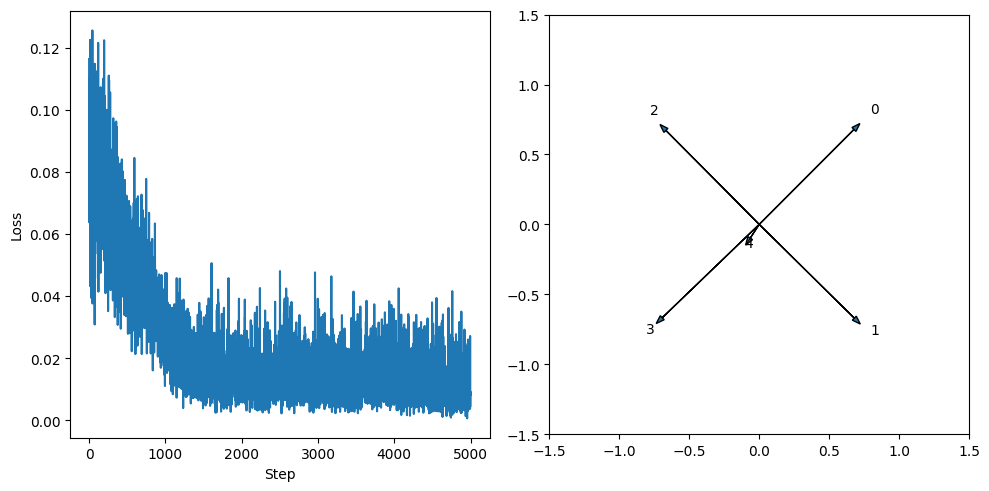

In [4]:
import torch.nn as nn
import torch.optim as optim

def train(model, sparcity, importance, steps = 5000, batch_size = 64, lr = 1e-3):
    opt = optim.Adam(model.parameters(), lr = lr)
    losses = []
    for step in range(steps):
      x = generate_batch(batch_size, model.W.shape[1], sparcity)
      x_hat, _ = model(x)
      loss = weighted_loss(x, x_hat, importance)
      opt.zero_grad()
      loss.backward()
      opt.step()
      losses.append(loss.item())
    return losses

torch.manual_seed(0)
model = toy_model(n_features=5, n_hidden=2)
losses = train(model, 0.9, importance)

W = model.W.detach()
b = model.b.detach()
gram = W.T @ W

print("final loss : ", losses[-1])
print("arrow length - ", gram.diag().sqrt())
print("bial b - ", b)

fig, axis = plt.subplots(1, 2, figsize=(10, 5))
axis[0].plot(losses)
axis[0].set_xlabel("Step")
axis[0].set_ylabel("Loss")

for i in range(5):
  axis[1].arrow(0, 0, W[0, i], W[1, i], head_width= 0.04 , length_includes_head=True)
  axis[1].text(W[0, i] * 1.1, W[1, i] * 1.1 , f"{i}")

axis[1].set_xlim(-1.5, 1.5)
axis[1].set_ylim(-1.5, 1.5)
axis[1].set_aspect("equal")
plt.tight_layout()
plt.show()

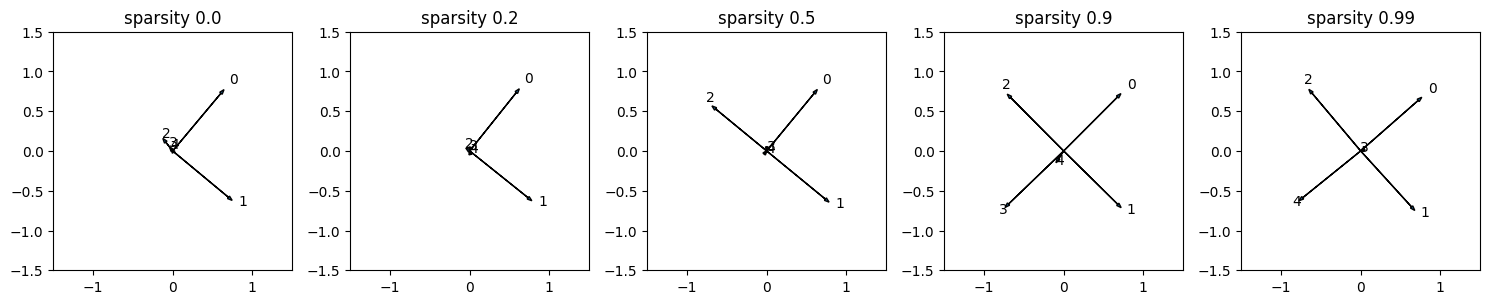

In [14]:
#try with different sparcity
sparcities = [0.0, 0.2, 0.5, 0.9, 0.99]
fig, axis = plt.subplots(1, len(sparcities), figsize=(15, 5))

for ax, S in zip(axis, sparcities):
    torch.manual_seed(0)
    m = toy_model(5, 2) # feature, dimensions
    losses = train(m, S, importance)
    W = m.W.detach() # 2, 5
    lengths = W.norm(dim=0)
    for i in range(5):
      ax.arrow(0, 0, W[0, i].item(), W[1, i].item(), head_width= 0.04 , length_includes_head=True)
      ax.text(W[0, i].item() * 1.1, W[1, i].item() * 1.1 , f"{i}")
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal")
    ax.set_title(f"sparsity {S}")


plt.tight_layout()
plt.show()


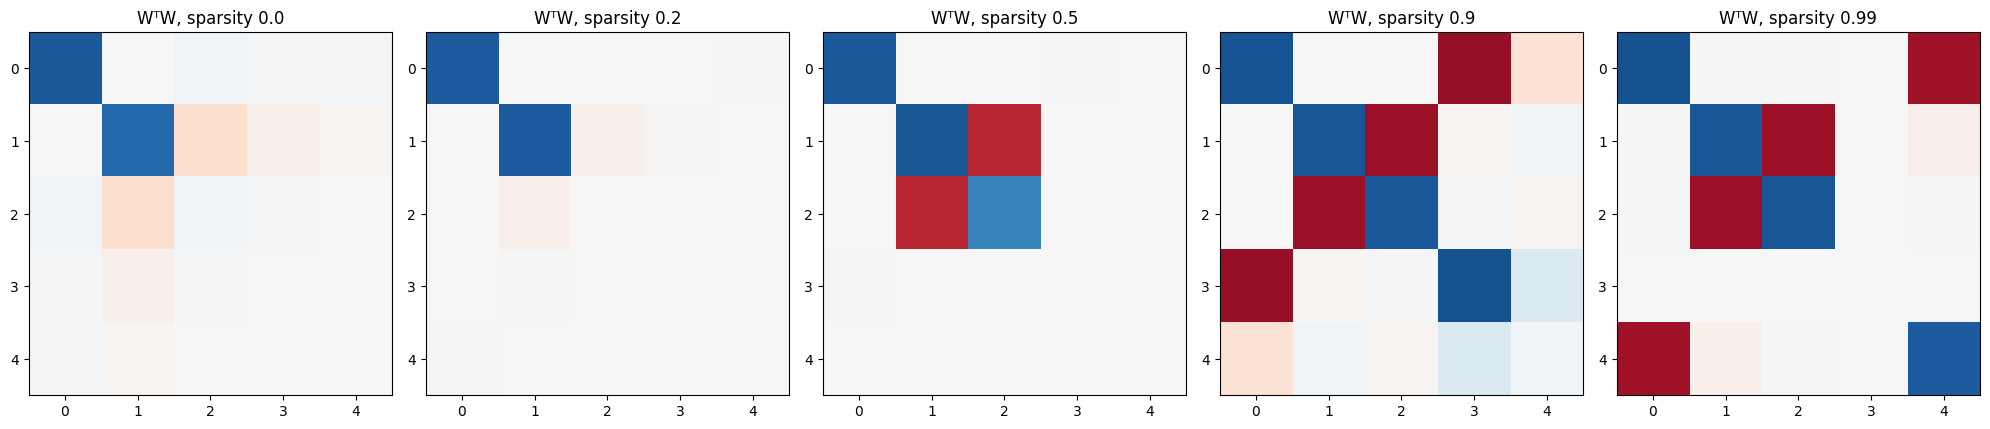

lengths: [1.02 1.02 1.01 1.02 0.18]
cosine similarity:
 [[ 1.    0.01  0.   -1.   -0.98]
 [ 0.01  1.   -1.   -0.03  0.2 ]
 [ 0.   -1.    1.    0.02 -0.21]
 [-1.   -0.03  0.02  1.    0.97]
 [-0.98  0.2  -0.21  0.97  1.  ]]


In [15]:
sparsities = [0.0, 0.2, 0.5, 0.9, 0.99]
models = {}
for S in sparsities:
    torch.manual_seed(0)
    m = toy_model(5, 2)              # use your class name
    train(m, S, importance)
    models[S] = m

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, S in zip(axes, sparsities):
    W = models[S].W.detach()                    # (2, 5)
    G = W.T @ W                                 # (5, 5)
    assert torch.allclose(G, torch.einsum("ki,kj->ij", W, W), atol=1e-6)
    assert torch.allclose(G.diag(), W.norm(dim=0) ** 2, atol=1e-6)
    ax.imshow(G, cmap="RdBu", vmin=-1.2, vmax=1.2)
    ax.set_title(f"WᵀW, sparsity {S}")
plt.tight_layout(); plt.show()

# Cosine check at S = 0.9
W = models[0.9].W.detach()
lengths = W.norm(dim=0)                                          # (5,)
cos = (W.T @ W) / (lengths[:, None] * lengths[None, :] + 1e-8)   # (5, 5)
print("lengths:", lengths.numpy().round(2))
print("cosine similarity:\n", cos.numpy().round(2))

* S = 0 and 0.2: only features 0 and 1 have blue diagonals, with nothing strong off the diagonal. That’s two features on two orthogonal axes, with no interference.
* S = 0.5: features 0, 1 and 2 are represented, and the (1,2) cell is red. Features 1 and 2 are antipodal, the first appearance of superposition. Feature 2’s diagonal is lighter than the others, which suggests it’s only partly represented. Check its length in your printed output.
* S = 0.9: four blue diagonals (0 to 3) and dark red at (0,3) and (1,2). Those are the two antipodal pairs, and every cross-pair cell is near zero. Feature 4 has almost no diagonal, so it was dropped. The faint colors in its row are noise from an arrow with almost no length.
* S = 0.99: the pairs are now (0,4) and (1,2), and feature 3’s row and column are completely blank. So the heatmap confirms what we suspected from the arrow plot. The model dropped feature 3 and kept feature 4, even though 3 is slightly more important. Seeds 1, 2 and 3 will tell you whether that’s an initialization accident.